In [1]:
import pandas as pd

data = pd.read_csv('../Dataset/CVF Conferences Dataset.csv')

In [2]:
import re
from bs4 import BeautifulSoup
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

class Preprocessing:
    def __init__(self):
        self.lemmatizer = WordNetLemmatizer()
        self.stop_words = set(stopwords.words('english'))

    def cleanHTML_attribute(self, text):
        new_text = re.sub(r'[\r\n\t]', '', text)
        return BeautifulSoup(new_text, "html.parser").get_text()

    def cleanText(self, text):
        text = re.sub('https?:\/\/\S+', '', text)
        text = re.sub('[^a-zA-Z]', ' ', str(text).lower().strip())
        text = re.sub('#', '', text)
        text = re.sub('\d+', '', text)
        text = re.sub('[!"#$%&\()*+,-./:;<=>?@[\\]^_`{|}~]+', '', text)
        text = re.sub('\n', ' ', text)
        return text

    def removeStopwords(self, text):
        tokens = word_tokenize(text)
        clean_text = [self.lemmatizer.lemmatize(word) for word in tokens if word.lower() not in self.stop_words]
        return ' '.join(clean_text)

    def removeSuffix(self, text):
        text = re.sub(r'\b(\w+?)s\b', r'\1', text)
        return text

    def preprocess(self, text):
        text = self.cleanHTML_attribute(text)
        text = self.cleanText(text)
        text = self.removeStopwords(text)
        text = self.removeSuffix(text)
        return text

In [3]:
preprocessing = Preprocessing()
data['Clean Abstract'] = data['Abstract'].astype(str).apply(preprocessing.preprocess)

In [4]:
from dotenv import load_dotenv
import os

load_dotenv()
cohere_api_key = os.getenv('COHERE_API_KEY')
gemini_api_key = os.getenv('GEMINI_API_KEY')

In [5]:
# import cohere
# import numpy
# from bertopic.backend import CohereBackend

# client = cohere.Client(cohere_api_key)
# embedding_model = CohereBackend(client=client, embedding_model='embed-english-v2.0')
# response = client.embed(texts=data['Clean Abstract'].tolist(), model='embed-english-v2.0')
# embeddings = numpy.array(response.embeddings)

In [6]:
from sentence_transformers import SentenceTransformer

data = data.reset_index(drop=True)
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")
embeddings = embedding_model.encode(data['Clean Abstract'], show_progress_bar=True)

Batches:   0%|          | 0/661 [00:00<?, ?it/s]

In [7]:
prompt = """
Based on these Keywords, determine a relevant label that accurately represents the overall topic in 5 words or fewer.
"""

In [8]:
from langchain.chains.question_answering import load_qa_chain
from langchain_google_genai import ChatGoogleGenerativeAI

llm = ChatGoogleGenerativeAI(
    google_api_key=gemini_api_key,
    model="gemini-pro",
    temperature=0.6,
    topK=1,
    topP=0.6,
    convert_system_message_to_human=True
)

chain = load_qa_chain(llm, chain_type="stuff")

In [10]:
from bertopic.representation import LangChain

representation_model = LangChain(chain, prompt=prompt)

In [11]:
from transformers.pipelines import pipeline
from bertopic.representation import TextGeneration
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer
from bertopic.vectorizers import ClassTfidfTransformer

umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric='cosine')
hdbscan_model = HDBSCAN(min_cluster_size=15, metric='euclidean', cluster_selection_method='eom', prediction_data=True)
vectorizer_model = CountVectorizer(stop_words="english")
ctfidf_model = ClassTfidfTransformer()

In [12]:
from bertopic import BERTopic

topic_model = BERTopic(
    embedding_model=embedding_model,    # Step 1 - Extract embeddings
    umap_model=umap_model,              # Step 2 - Reduce dimensionality
    hdbscan_model=hdbscan_model,        # Step 3 - Cluster reduced embeddings
    vectorizer_model=vectorizer_model,  # Step 4 - Tokenize topics
    ctfidf_model=ctfidf_model,          # Step 5 - Extract topic words
    representation_model={
        'Gemini': representation_model
    },
    nr_topics=35,
    verbose=True,
)

In [13]:
topics, probs = topic_model.fit_transform(data['Clean Abstract'], embeddings)

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.
2024-06-25 20:06:41,661 - BERTopic - Reduced dimensionality
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid

In [14]:
topic_model.visualize_barchart(top_n_topics=10, n_words=10)

In [15]:
all_topics = topic_model.get_topic_info()
all_topics

,Topic,Count,Name,Representation,Gemini,Representative_Docs
0,-1,6689,-1_image_model_method_dataset,"[image, model, method, dataset, object, video,...","[Semi-supervised learning for image tasks, , ,...",[development computational power technique dat...
1,0,2026,0_visual_model_task_text,"[visual, model, task, text, learning, image, s...","[Zero-shot learning with generative models, , ...",[existing method using generative adversarial ...
2,1,1908,1_video_action_frame_tracking,"[video, action, frame, tracking, temporal, flo...",[Self-supervised video representation learning...,[existing siamese tracking method built pair w...
3,2,1385,2_depth_point_scene_view,"[depth, point, scene, view, cloud, method, sur...",[Implicit neural representation for novel view...,[paper tackle problem novel view synthesi sing...
4,3,1319,3_pose_person_hand_human,"[pose, person, hand, human, estimation, body, ...","[Hand pose estimation from images, , , , , , ,...",[rgb based hand pose estimation successful dec...
5,4,1241,4_object_segmentation_detection_detector,"[object, segmentation, detection, detector, se...","[Self-supervised semantic segmentation, , , , ...",[weakly supervised semantic segmentation image...
6,5,885,5_image_rain_method_blur,"[image, rain, method, blur, network, shadow, r...","[Non-blind motion deblurring, , , , , , , , , ]",[design novel network architecture learning di...
7,6,675,6_domain_label_clas_source,"[domain, label, clas, source, data, sample, ta...","[Domain adaptation learning, , , , , , , , , ]",[domain adaptation aim transfer knowledge lear...
8,7,543,7_style_gan_image_sketch,"[style, gan, image, sketch, transfer, generati...","[Style transfer without reference images, , , ...",[given random pair image universal style trans...
9,8,499,8_face_facial_landmark_expression,"[face, facial, landmark, expression, age, au, ...","[Face Deblurring and Reconstruction, , , , , ,...",[deep network trained million facial image bel...


In [16]:
gemini_labels = [re.sub(r'\W+', ' ', label[0][0].split("\n")[0].replace('"', '')) for label in topic_model.get_topics(full=True)["Gemini"].values()]
gemini_labels = [label if label else "Unlabelled" for label in gemini_labels]
all_labels = [gemini_labels[topic+topic_model._outliers] if topic != -1 else "Unlabelled" for topic in topics]

In [17]:
reduced_embeddings = UMAP(n_neighbors=10, n_components=2, min_dist=0.0, metric='cosine').fit_transform(embeddings)

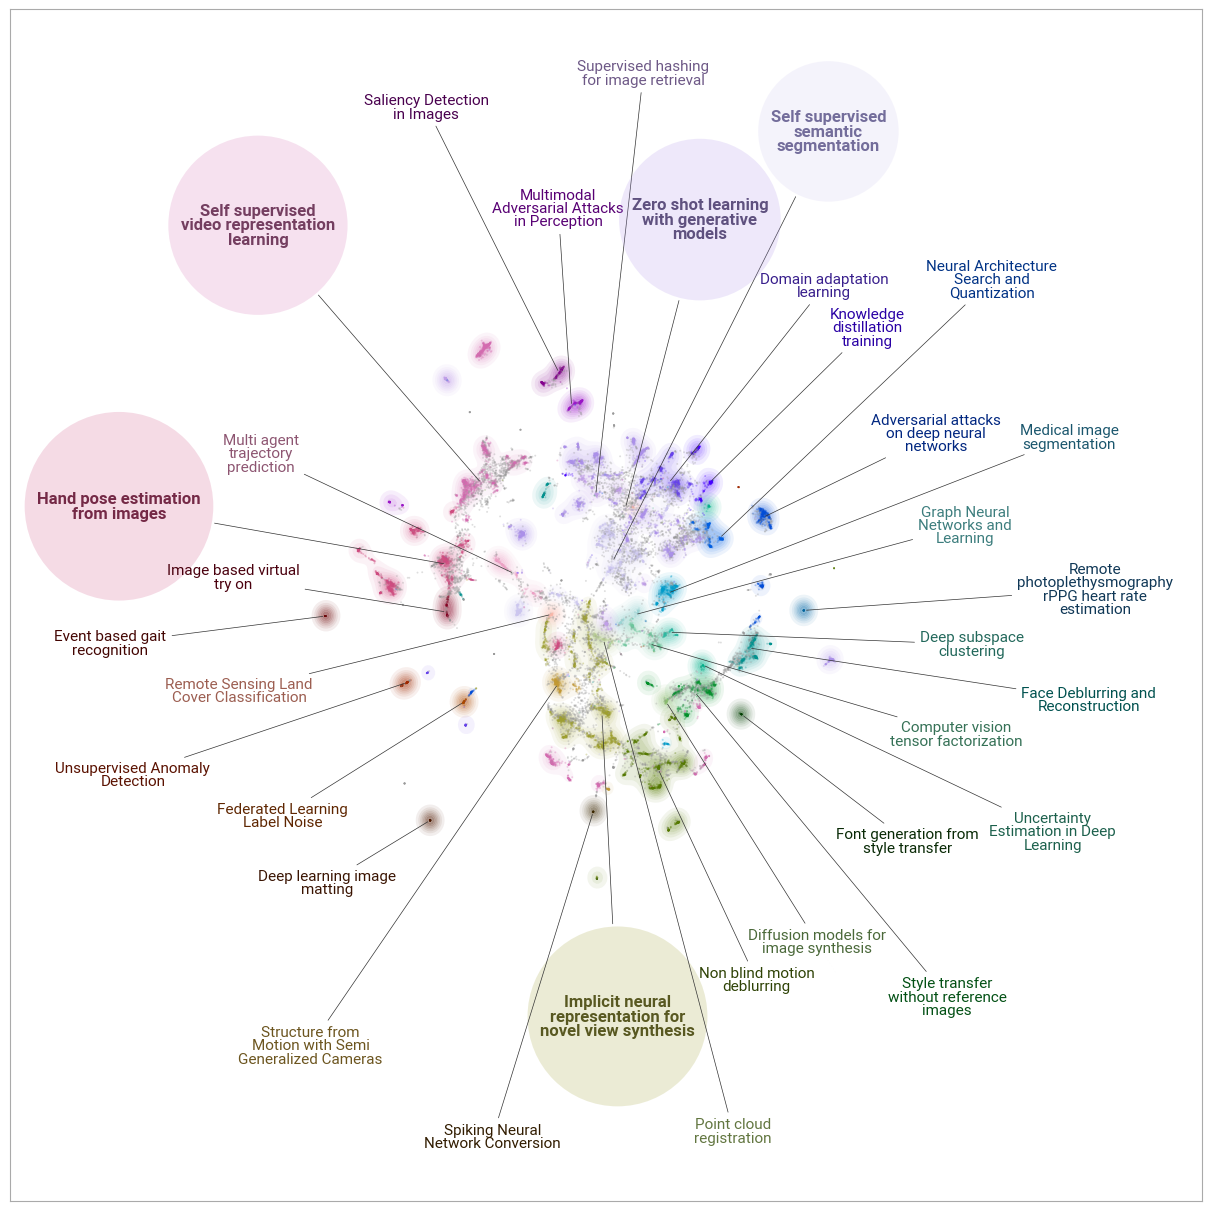

In [41]:
import datamapplot

# Run the visualization
datamapplot.create_plot(
    reduced_embeddings,
    all_labels,
    label_font_size=11,
    label_wrap_width=20,
    highlight_labels=[
        'Zero shot learning with generative models',
        'Self supervised video representation learning',
        'Implicit neural representation for novel view synthesis',
        'Hand pose estimation from images',
        'Self supervised semantic segmentation',
    ],
    highlight_label_keywords={"fontsize": 12, "fontweight": "bold", "bbox":{"boxstyle":"circle", "pad":0.75}},
    use_medoids=True,
);

  0%|          | 0/500 [00:00<?, ?it/s]

Resetting positions to accord with alignment


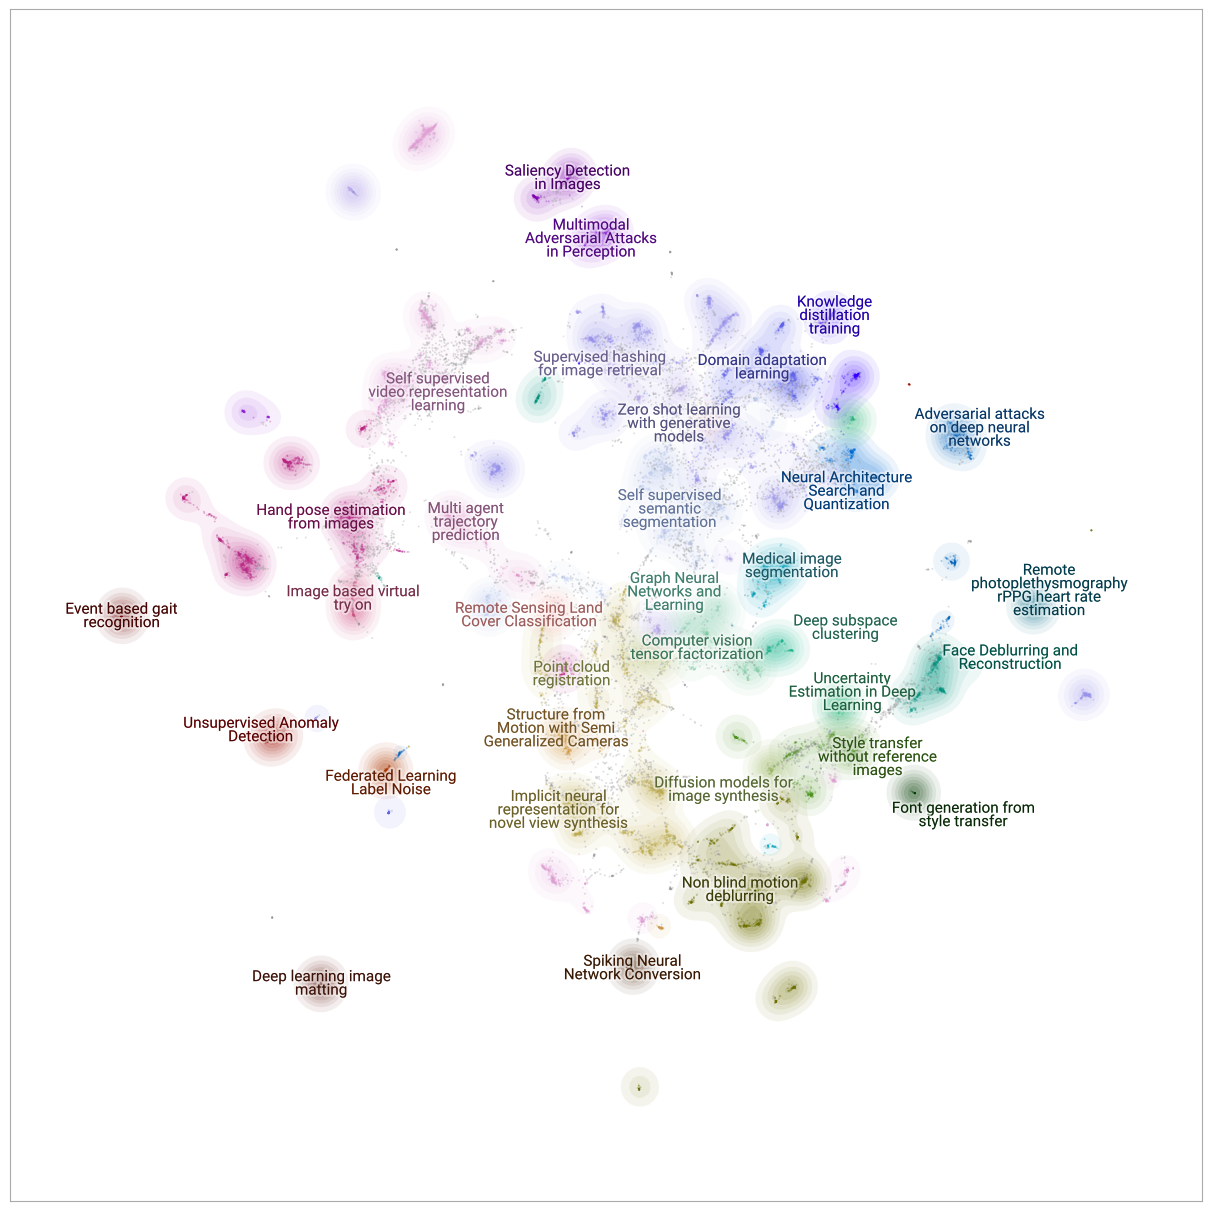

In [42]:
datamapplot.create_plot(
    reduced_embeddings,
    all_labels,
    label_font_size=11,
    label_wrap_width=20,
    use_medoids=True,
    label_over_points=True,
    dynamic_label_size=True,
);

In [33]:
data['timestamp'] = data['CVF Conferences'].str.extract(r'(\d{4})')
timestamps = data['timestamp'].to_list()

In [21]:
topic_labels_dict = {i - 1: label for i, label in enumerate(gemini_labels)}
topic_model.set_topic_labels(topic_labels_dict)

In [31]:
topics_over_time = topic_model.topics_over_time(data['Clean Abstract'].to_list(), timestamps)
topic_model.visualize_topics_over_time(topics_over_time, topics=[0,1,2,3,4,5,6,7,8,9], custom_labels=True, title="")

11it [00:02,  4.10it/s]


In [32]:
topics_over_time = topic_model.topics_over_time(data['Clean Abstract'].to_list(), timestamps)
topic_model.visualize_topics_over_time(topics_over_time, topics=[0,1,2,3,4], custom_labels=True, title="")

11it [00:02,  4.08it/s]
